In [2]:
#Checking in-situ data for quality control - range, missing values, extreme values

#loading libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#loading datasets
t_max_data1 = pd.read_csv(r"..\Data\Raw\max.csv")
t_min_data1 = pd.read_csv(r"..\Data\Raw\min.csv")
rain_data1 = pd.read_csv(r"..\Data\Raw\rain.csv")
station_data1 = pd.read_excel(r"..\Data\Raw\met_station.xlsx")

station_data = pd.DataFrame()
station_data[['index_no','station_name', 'district', 'lat', 'long', 'elevation']] = station_data1[['Index No.','Station Name', 'District', 'Lat', 'Lon', 'Elev']].copy()
station_data

FileNotFoundError: [Errno 2] No such file or directory: '..\\Data\\Raw\\max.csv'

In [54]:
#Preparing datasets for merge
t_max_data1['merge_id'] = t_max_data1['index_no'].astype(str) + '_' + t_max_data1['year'].astype(str) + '_' + t_max_data1['month'].astype(str) + '_' + t_max_data1['day'].astype(str)
t_min_data1['merge_id'] = t_min_data1['index_no'].astype(str) + '_' + t_min_data1['year'].astype(str) + '_' + t_min_data1['month'].astype(str) + '_' + t_min_data1['day'].astype(str)
rain_data1['merge_id'] = rain_data1['index_no'].astype(str) + '_' + rain_data1['year'].astype(str) + '_' + rain_data1['month'].astype(str) + '_' + rain_data1['day'].astype(str)

#merging datasets by merge_id
insitu_data_merged1 = t_max_data1.merge(t_min_data1[['merge_id','min_temp',]], how = 'outer', on='merge_id')
insitu_data_merged2 = insitu_data_merged1.merge(rain_data1[['merge_id','rainfall_sum']], how = 'outer', on='merge_id')
insitu_data_merged2

,gsid,index_no,station,district,year,month,day,max_temp,merge_id,min_temp,rainfall_sum
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1004_1980_10_1,NaN,10.5
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1004_1980_10_10,NaN,0.0
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1004_1980_10_11,NaN,10.5
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1004_1980_10_12,NaN,0.0
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1004_1980_10_13,NaN,15.3
...,...,...,...,...,...,...,...,...,...,...,...
1357961,289.0,922.0,Gaur,Routahat,2020.0,9.0,5.0,40.2,922_2020_9_5,25.1,NaN
1357962,289.0,922.0,Gaur,Routahat,2020.0,9.0,6.0,39.1,922_2020_9_6,25.1,NaN
1357963,289.0,922.0,Gaur,Routahat,2020.0,9.0,7.0,39.1,922_2020_9_7,26.2,NaN
1357964,289.0,922.0,Gaur,Routahat,2020.0,9.0,8.0,40.1,922_2020_9_8,25.1,NaN


In [55]:
#generating missing values of index_no, year, month, day from merge_id
insitu_data_merged2[['index_no','year','month','day']] = insitu_data_merged2['merge_id'].str.split('_', expand=True)[[0,1,2,3]]
df_insitu_merged = insitu_data_merged2[['index_no','year','month','day','max_temp','min_temp','rainfall_sum']]
df_insitu_merged = df_insitu_merged.copy()
df_insitu_merged.loc[:, 'index_no'] = df_insitu_merged['index_no'].astype(int)
df_insitu_merged


,index_no,year,month,day,max_temp,min_temp,rainfall_sum
0,1004,1980,10,1,NaN,NaN,10.5
1,1004,1980,10,10,NaN,NaN,0.0
2,1004,1980,10,11,NaN,NaN,10.5
3,1004,1980,10,12,NaN,NaN,0.0
4,1004,1980,10,13,NaN,NaN,15.3
...,...,...,...,...,...,...,...
1357961,922,2020,9,5,40.2,25.1,NaN
1357962,922,2020,9,6,39.1,25.1,NaN
1357963,922,2020,9,7,39.1,26.2,NaN
1357964,922,2020,9,8,40.1,25.1,NaN


In [56]:
#from station_data we add station name and coordinates to the insitu data
df_insitu_final = df_insitu_merged.merge(station_data[['index_no','station_name', 'district', 'lat', 'long', 'elevation']], how='left', on='index_no')
df_insitu_final = df_insitu_final.sort_values(by=['index_no','year','month','day'])


#select rows with na values for latitude and checking corresponding index_no
na_latitude = df_insitu_final[df_insitu_final['lat'].isna()]
na_index_nos = na_latitude['index_no'].unique()
print(na_index_nos)

df_insitu_final = df_insitu_final[~df_insitu_final['index_no'].isin(na_index_nos)]
index_list = df_insitu_final['index_no'].unique()
print(index_list)

df_insitu_final = df_insitu_final[['index_no','station_name', 'district', 'lat', 'long', 'elevation','year','month','day','max_temp','min_temp','rainfall_sum']]
df_insitu_final

[405]
[102 103 104 105 107 202 203 204 207 215 217 306 308 310 311 312 334 399
 401 404 408 409 416 504 505 508 511 513 601 604 605 607 609 612 614 616
 702 703 705 706 708 715 716 725 802 805 808 809 810 814 815 816 871 902
 905 906 909 918 921 922 1004 1005 1007 1009 1016 1022 1024 1027 1029 1030
 1036 1038 1043 1052 1055 1057 1071 1102 1103 1107 1111 1118 1122 1123
 1206 1212 1213 1215 1219 1222 1223 1225 1303 1304 1310 1311 1314 1318
 1319 1320 1324 1407 1408 1412 1416 1419]


,index_no,station_name,district,lat,long,elevation,year,month,day,max_temp,min_temp,rainfall_sum
124578,102,Baitadi_Gothapani,Baitadi,29.55744,80.41317,1352.0,1980,1,1,NaN,NaN,7.5
124579,102,Baitadi_Gothapani,Baitadi,29.55744,80.41317,1352.0,1980,1,10,NaN,NaN,0.0
124580,102,Baitadi_Gothapani,Baitadi,29.55744,80.41317,1352.0,1980,1,11,NaN,NaN,0.0
124581,102,Baitadi_Gothapani,Baitadi,29.55744,80.41317,1352.0,1980,1,12,NaN,NaN,0.0
124582,102,Baitadi_Gothapani,Baitadi,29.55744,80.41317,1352.0,1980,1,13,NaN,NaN,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
674584,1419,Phidim,Panchther,27.14367,87.76560,1157.0,2020,9,5,28.5,21.5,0.0
674585,1419,Phidim,Panchther,27.14367,87.76560,1157.0,2020,9,6,29.0,21.5,0.0
674586,1419,Phidim,Panchther,27.14367,87.76560,1157.0,2020,9,7,28.5,21.0,5.5
674587,1419,Phidim,Panchther,27.14367,87.76560,1157.0,2020,9,8,25.5,21.0,6.8


In [57]:
#for each station findout the start and end date, with number of observations in form - 
#stationID, rainfall_start, rainfall_end, rainfall_obs, max_temp_start, max_temp_end, max_temp_obs, min_temp_start, min_temp_end, min_temp_obs

# Create empty lists to store results
results = []

for station in index_list:
    # Filter data for current station
    station_data = df_insitu_final[df_insitu_final['index_no'] == station]
    
    # Rainfall data
    rain_data = station_data[station_data['rainfall_sum'].notna()]
    if len(rain_data) > 0:
        rain_start = rain_data[['year', 'month', 'day']].iloc[0]
        rain_end = rain_data[['year', 'month', 'day']].iloc[-1]
        rain_obs = len(rain_data)
    else:
        rain_start = pd.Series({'year': None, 'month': None, 'day': None})
        rain_end = pd.Series({'year': None, 'month': None, 'day': None})
        rain_obs = 0
    
    # Max temperature data
    max_temp_data = station_data[station_data['max_temp'].notna()]
    if len(max_temp_data) > 0:
        max_start = max_temp_data[['year', 'month', 'day']].iloc[0]
        max_end = max_temp_data[['year', 'month', 'day']].iloc[-1]
        max_obs = len(max_temp_data)
    else:
        max_start = pd.Series({'year': None, 'month': None, 'day': None})
        max_end = pd.Series({'year': None, 'month': None, 'day': None})
        max_obs = 0
    
    # Min temperature data
    min_temp_data = station_data[station_data['min_temp'].notna()]
    if len(min_temp_data) > 0:
        min_start = min_temp_data[['year', 'month', 'day']].iloc[0]
        min_end = min_temp_data[['year', 'month', 'day']].iloc[-1]
        min_obs = len(min_temp_data)
    else:
        min_start = pd.Series({'year': None, 'month': None, 'day': None})
        min_end = pd.Series({'year': None, 'month': None, 'day': None})
        min_obs = 0
    
    # Append results to list
    results.append({
        'stationID': station,
        'rainfall_start': f"{rain_start['year']}-{rain_start['month']}-{rain_start['day']}" if rain_start['year'] is not None else None,
        'rainfall_end': f"{rain_end['year']}-{rain_end['month']}-{rain_end['day']}" if rain_end['year'] is not None else None,
        'rainfall_obs': rain_obs,
        'max_temp_start': f"{max_start['year']}-{max_start['month']}-{max_start['day']}" if max_start['year'] is not None else None,
        'max_temp_end': f"{max_end['year']}-{max_end['month']}-{max_end['day']}" if max_end['year'] is not None else None,
        'max_temp_obs': max_obs,
        'min_temp_start': f"{min_start['year']}-{min_start['month']}-{min_start['day']}" if min_start['year'] is not None else None,
        'min_temp_end': f"{min_end['year']}-{min_end['month']}-{min_end['day']}" if min_end['year'] is not None else None,
        'min_temp_obs': min_obs
    })

# Convert results to DataFrame and save to CSV
results_df = pd.DataFrame(results)
results_df.to_csv(r'..\Data\Processed\Insitu\insitu_period_1990_2019.csv', index=False)
print(results_df)

     stationID rainfall_start rainfall_end  rainfall_obs max_temp_start  \
0          102       1980-1-1     2020-9-9         14762      2010-1-24   
1          103       1980-1-1     2020-6-9         14763       1981-1-1   
2          104       1980-1-1     2020-9-9         14976       1980-1-1   
3          105       1980-1-1     2020-9-9         12705       1980-1-1   
4          107       1980-1-1     2019-9-9         14549      1989-10-1   
..         ...            ...          ...           ...            ...   
101       1407       1980-1-1     2020-9-9         13614       1980-1-1   
102       1408       1980-1-1     2020-9-9         14852      2013-10-1   
103       1412       1980-1-1     2020-9-9         14852      2011-10-1   
104       1416       1980-1-1     2020-9-9         14371       1980-1-1   
105       1419       1980-1-1     2020-9-9         14931      1989-10-1   

    max_temp_end  max_temp_obs min_temp_start min_temp_end  min_temp_obs  
0       2020-9-9        

In [58]:
#checking data avaliability for period 1990-2019 for each station
data_percentage = {}

for station in index_list:
    station_data = df_insitu_final[df_insitu_final['index_no'] == station]
    #exact days from 1990 to 2020
    total_days = pd.date_range(start='1990-01-01', end='2019-12-31', freq='D')
    total_days_count = len(total_days)
    #days with data for rainfall
    rain_days = station_data[station_data['rainfall_sum'].notna()]
    rain_days['date'] = pd.to_datetime(station_data[['year', 'month', 'day']])
    rain_days_count = len(rain_days[rain_days['date'].between('1990-01-01', '2019-12-31')])
    #calculating percentage
    rain_data_percentage = (rain_days_count / total_days_count) * 100
    data_percentage.setdefault(station, {})['rainfall_data_percentage'] = rain_data_percentage
    #days with data for max temp
    max_days = station_data[station_data['max_temp'].notna()]
    max_days['date'] = pd.to_datetime(station_data[['year', 'month', 'day']])
    max_days_count = len(max_days[max_days['date'].between('1990-01-01', '2019-12-31')])
    #calculating percentage
    max_data_percentage = (max_days_count / total_days_count) * 100
    data_percentage.setdefault(station, {})['max_temp_data_percentage'] = max_data_percentage
    #days with data for min temp
    min_days = station_data[station_data['min_temp'].notna()]
    min_days['date'] = pd.to_datetime(station_data[['year', 'month', 'day']])
    min_days_count = len(min_days[min_days['date'].between('1990-01-01', '2019-12-31')])
    #calculating percentage
    min_data_percentage = (min_days_count / total_days_count) * 100
    data_percentage.setdefault(station, {})['min_temp_data_percentage'] = min_data_percentage

#convert to DataFrame
data_percentage_df = pd.DataFrame.from_dict(data_percentage, orient='index')
data_percentage_df.to_csv(r'..\Data\Processed\Insitu\station_data_percentage_1990_2019.csv')
print(data_percentage_df)


      rainfall_data_percentage  max_temp_data_percentage  \
102                  98.046911                 28.967783   
103                 100.000000                 96.623163   
104                 100.000000                 99.963494   
105                  93.118554                 93.091175   
107                  99.443278                 97.097746   
...                        ...                       ...   
1407                 90.946427                 83.061057   
1408                 99.142101                 21.447476   
1412                 98.886557                 26.850415   
1416                 94.478416                 90.700009   
1419                 99.589304                 97.544948   

      min_temp_data_percentage  
102                  32.107329  
103                  90.773022  
104                  99.561924  
105                  91.274984  
107                  97.928265  
...                        ...  
1407                 81.819841  
1408           

In [59]:
#print no of statations with >80% data availability for each parameter
rainfall_stations_80 = data_percentage_df[data_percentage_df['rainfall_data_percentage'] > 80]
max_temp_stations_80 = data_percentage_df[data_percentage_df['max_temp_data_percentage'] > 80]
min_temp_stations_80 = data_percentage_df[data_percentage_df['min_temp_data_percentage'] > 80]
print("Stations with >80% Rainfall Data Availability:", len(rainfall_stations_80))
print("Stations with >80% Max Temp Data Availability:", len(max_temp_stations_80))
print("Stations with >80% Min Temp Data Availability:", len(min_temp_stations_80))

Stations with >80% Rainfall Data Availability: 86
Stations with >80% Max Temp Data Availability: 60
Stations with >80% Min Temp Data Availability: 60


In [60]:
import ee
import geemap
from ipyleaflet import Marker, Icon, MarkerCluster

# Authenticate and initialize
ee.Authenticate()
ee.Initialize(project='ee-jeevankatel3')

# Create map (ipyleaflet backend)
m = geemap.Map(center=[29.5, 80.4], zoom=8)

# Create clusters for each group
cluster_rain = MarkerCluster(name='Rainfall >80%')
cluster_max = MarkerCluster(name='MaxTemp >80%')
cluster_min = MarkerCluster(name='MinTemp >80%')

# Add rainfall stations
for station in rainfall_stations_80.index:
    station_info = df_insitu_final[df_insitu_final['index_no'] == station].iloc[0]
    lat = float(station_info['lat'])
    lon = float(station_info['long'])
    name = str(station_info['station_name'])
    icon = Icon(icon_url='https://maps.gstatic.com/mapfiles/ms2/micons/blue-dot.png', icon_size=[24, 24])
    marker = Marker(location=(lat, lon), title=name, icon=icon)
    cluster_rain.markers = cluster_rain.markers + (marker,)  # ← FIXED: add tuple not list

# Add max temperature stations
for station in max_temp_stations_80.index:
    station_info = df_insitu_final[df_insitu_final['index_no'] == station].iloc[0]
    lat = float(station_info['lat'])
    lon = float(station_info['long'])
    name = str(station_info['station_name'])
    icon = Icon(icon_url='https://maps.gstatic.com/mapfiles/ms2/micons/red-dot.png', icon_size=[24, 24])
    marker = Marker(location=(lat, lon), title=name, icon=icon)
    cluster_max.markers = cluster_max.markers + (marker,)

# Add min temperature stations
for station in min_temp_stations_80.index:
    station_info = df_insitu_final[df_insitu_final['index_no'] == station].iloc[0]
    lat = float(station_info['lat'])
    lon = float(station_info['long'])
    name = str(station_info['station_name'])
    icon = Icon(icon_url='https://maps.gstatic.com/mapfiles/ms2/micons/green-dot.png', icon_size=[24, 24])
    marker = Marker(location=(lat, lon), title=name, icon=icon)
    cluster_min.markers = cluster_min.markers + (marker,)

# Add clusters as layers
m.add_layer(cluster_rain)
m.add_layer(cluster_max)
m.add_layer(cluster_min)

# Add layer control
m.add_layer_control()

# Display
m


Map(center=[29.5, 80.4], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', …

Text(0, 0.5, 'Elevation (m)')

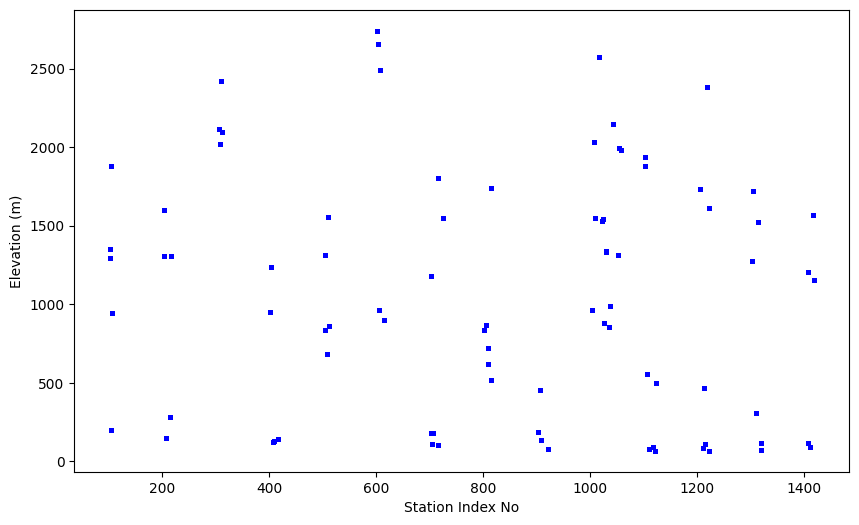

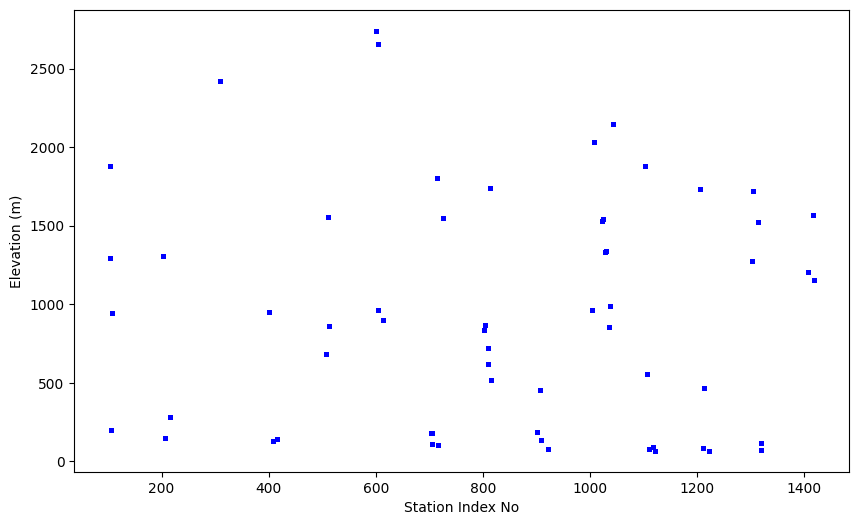

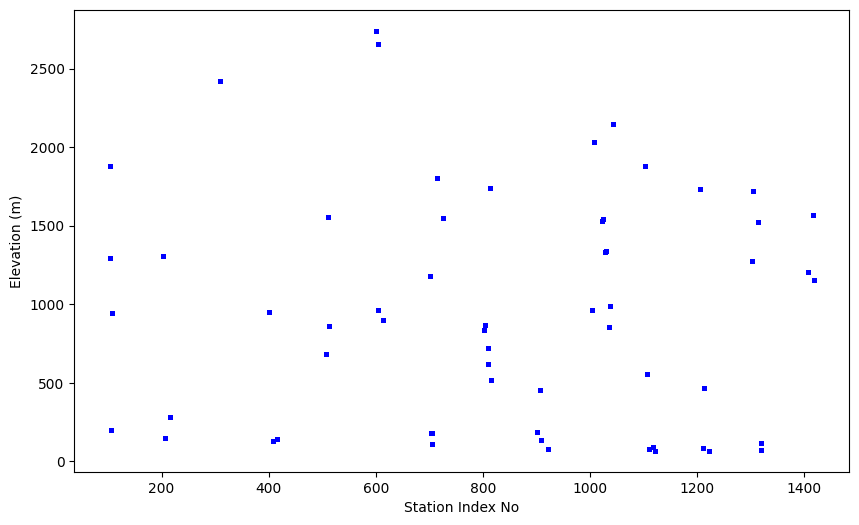

In [61]:
#get list of stations with >80% data availability
list_tmax_stn = list(max_temp_stations_80.index)
list_tmin_stn = list(min_temp_stations_80.index)
list_rain_stn = list(rainfall_stations_80.index)

#cut original dataframe to include - qualified stations, date from 1990-2019
df_insitu_rainfall = df_insitu_final[
    (df_insitu_final['index_no'].isin(list_rain_stn)) &
    (pd.to_datetime(df_insitu_final[['year', 'month', 'day']]).between('1990-01-01', '2019-12-31'))
]

df_insitu_maxtemp = df_insitu_final[
    (df_insitu_final['index_no'].isin(list_tmax_stn)) &
    (pd.to_datetime(df_insitu_final[['year', 'month', 'day']]).between('1990-01-01', '2019-12-31'))
]

df_insitu_mintemp = df_insitu_final[
    (df_insitu_final['index_no'].isin(list_tmin_stn)) &
    (pd.to_datetime(df_insitu_final[['year', 'month', 'day']]).between('1990-01-01', '2019-12-31'))     
]

#matplotlib to visualize elevation distribution of stations
plt.figure(figsize=(10,6))
plt.scatter(df_insitu_rainfall['index_no'], df_insitu_rainfall['elevation'], s=5, color='blue')
plt.xlabel('Station Index No')
plt.ylabel('Elevation (m)')

plt.figure(figsize=(10,6))
plt.scatter(df_insitu_maxtemp['index_no'], df_insitu_maxtemp['elevation'], s=5, color='blue')
plt.xlabel('Station Index No')
plt.ylabel('Elevation (m)')

plt.figure(figsize=(10,6))
plt.scatter(df_insitu_mintemp['index_no'], df_insitu_mintemp['elevation'], s=5, color='blue')
plt.xlabel('Station Index No')
plt.ylabel('Elevation (m)')

In [62]:
#creating final dataframes with selected columns
df_insitu_mintemp = df_insitu_mintemp[['index_no','station_name', 'district', 'lat', 'long', 'elevation','year','month','day','min_temp']]
df_insitu_maxtemp = df_insitu_maxtemp[['index_no','station_name', 'district', 'lat', 'long', 'elevation','year','month','day','max_temp']]
df_insitu_rainfall = df_insitu_rainfall[['index_no','station_name', 'district', 'lat', 'long', 'elevation','year','month','day','rainfall_sum']]

df_insitu_rainfall.to_csv(r'..\Data\Processed\Insitu\insitu_rainfall_1990_2019.csv', index=False)
df_insitu_mintemp.to_csv(r'..\Data\Processed\Insitu\insitu_mintemp_1990_2019.csv', index=False)
df_insitu_rainfall.to_csv(r'..\Data\Processed\Insitu\insitu_maxtemp_1990_2019.csv', index=False)